# NYC Taxi Big Data Project
### Using Apache Spark | Yellow & Green Taxi 2024
Covers: Data Loading, Preprocessing, Visualization, Supervised Learning (Regression + Classification), K-Means Clustering, Neural Network

---
## 0. Install Dependencies

In [1]:
# Run this cell once to install required libraries
import subprocess
subprocess.run(['pip', 'install', 'pyspark', 'pandas', 'pyarrow', 'matplotlib', 'seaborn', 'scikit-learn', 'tensorflow'], check=True)

CompletedProcess(args=['pip', 'install', 'pyspark', 'pandas', 'pyarrow', 'matplotlib', 'seaborn', 'scikit-learn', 'tensorflow'], returncode=0)

---
## 1. Imports & Spark Session

In [2]:
import os
import warnings
warnings.filterwarnings('ignore')

# Spark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, IntegerType
from pyspark.ml.feature import VectorAssembler, StandardScaler, StringIndexer
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import RegressionEvaluator, MulticlassClassificationEvaluator
from pyspark.ml import Pipeline

# Data & Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Neural Network
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import StandardScaler as SklearnScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, classification_report

print('All imports successful!')
print(f'TensorFlow version: {tf.__version__}')

All imports successful!
TensorFlow version: 2.21.0


In [3]:
import subprocess
r = subprocess.run(['java', '-version'], capture_output=True, text=True)
print(r.stderr)

openjdk version "17.0.19" 2026-04-21
OpenJDK Runtime Environment Temurin-17.0.19+10 (build 17.0.19+10)
OpenJDK 64-Bit Server VM Temurin-17.0.19+10 (build 17.0.19+10, mixed mode, sharing)



In [4]:
# Start Spark Session
spark = SparkSession.builder \
    .appName('NYC Taxi Big Data Project') \
    .config('spark.driver.memory', '4g') \
    .config('spark.sql.shuffle.partitions', '50') \
    .getOrCreate()

spark.sparkContext.setLogLevel('ERROR')
print(f'Spark version: {spark.version}')
print('Spark session started successfully!')

Spark version: 4.1.1
Spark session started successfully!


---
## 2. Load Data

In [5]:
# File paths — all 7 files in your project folder
DATA_PATH = r'C:\Users\lpmoh\Big data project'

yellow_files = [
    os.path.join(DATA_PATH, 'yellow_tripdata_2024-01.parquet'),
    os.path.join(DATA_PATH, 'yellow_tripdata_2024-02.parquet'),
    os.path.join(DATA_PATH, 'yellow_tripdata_2024-03.parquet'),
]

green_files = [
    os.path.join(DATA_PATH, 'green_tripdata_2024-01.parquet'),
    os.path.join(DATA_PATH, 'green_tripdata_2024-02.parquet'),
    os.path.join(DATA_PATH, 'green_tripdata_2024-03.parquet'),
]

zone_file = os.path.join(DATA_PATH, 'taxi_zone_lookup.csv')

# Load Yellow Taxi
yellow_df = spark.read.parquet(*yellow_files)
yellow_df = yellow_df.withColumn('taxi_type', F.lit('yellow'))

# Load Green Taxi
green_df = spark.read.parquet(*green_files)
green_df = green_df.withColumn('taxi_type', F.lit('green'))

# Load Zone Lookup
zone_df = spark.read.csv(zone_file, header=True, inferSchema=True)

print(f'Yellow rows: {yellow_df.count():,}')
print(f'Green rows:  {green_df.count():,}')
print(f'Zones:       {zone_df.count():,}')

Yellow rows: 9,554,778
Green rows:  167,585
Zones:       265


In [6]:
# Preview Yellow schema
print('=== YELLOW SCHEMA ===')
yellow_df.printSchema()

print('\n=== GREEN SCHEMA ===')
green_df.printSchema()

=== YELLOW SCHEMA ===
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- taxi_type: string (nullable = false)


=== GREEN SCHEMA ===
root
 |-- VendorID: integer (nullable =

In [7]:
# Select common columns between yellow and green for merging
common_cols = [
    'taxi_type',
    F.col('tpep_pickup_datetime').alias('pickup_datetime') if 'tpep_pickup_datetime' in yellow_df.columns else F.col('lpep_pickup_datetime').alias('pickup_datetime'),
    F.col('tpep_dropoff_datetime').alias('dropoff_datetime') if 'tpep_dropoff_datetime' in yellow_df.columns else F.col('lpep_dropoff_datetime').alias('dropoff_datetime'),
    'passenger_count', 'trip_distance', 'PULocationID', 'DOLocationID',
    'fare_amount', 'tip_amount', 'total_amount', 'payment_type', 'RatecodeID'
]

yellow_sel = yellow_df.select(
    'taxi_type',
    F.col('tpep_pickup_datetime').alias('pickup_datetime'),
    F.col('tpep_dropoff_datetime').alias('dropoff_datetime'),
    'passenger_count', 'trip_distance', 'PULocationID', 'DOLocationID',
    'fare_amount', 'tip_amount', 'total_amount', 'payment_type', 'RatecodeID'
)

green_sel = green_df.select(
    'taxi_type',
    F.col('lpep_pickup_datetime').alias('pickup_datetime'),
    F.col('lpep_dropoff_datetime').alias('dropoff_datetime'),
    'passenger_count', 'trip_distance', 'PULocationID', 'DOLocationID',
    'fare_amount', 'tip_amount', 'total_amount', 'payment_type', 'RatecodeID'
)

# Combine both
df = yellow_sel.union(green_sel)
print(f'Combined rows: {df.count():,}')
df.show(3)

Combined rows: 9,722,363
+---------+-------------------+-------------------+---------------+-------------+------------+------------+-----------+----------+------------+------------+----------+
|taxi_type|    pickup_datetime|   dropoff_datetime|passenger_count|trip_distance|PULocationID|DOLocationID|fare_amount|tip_amount|total_amount|payment_type|RatecodeID|
+---------+-------------------+-------------------+---------------+-------------+------------+------------+-----------+----------+------------+------------+----------+
|   yellow|2024-01-01 00:57:55|2024-01-01 01:17:43|              1|         1.72|         186|          79|       17.7|       0.0|        22.7|           2|         1|
|   yellow|2024-01-01 00:03:00|2024-01-01 00:09:36|              1|          1.8|         140|         236|       10.0|      3.75|       18.75|           1|         1|
|   yellow|2024-01-01 00:17:06|2024-01-01 00:35:01|              1|          4.7|         236|          79|       23.3|       3.0|     

---
## 3. Data Preprocessing

In [8]:
# ── 3.1 Check Nulls ──
print('=== NULL COUNTS ===')
null_counts = df.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df.columns])
null_counts.show()

=== NULL COUNTS ===
+---------+---------------+----------------+---------------+-------------+------------+------------+-----------+----------+------------+------------+----------+
|taxi_type|pickup_datetime|dropoff_datetime|passenger_count|trip_distance|PULocationID|DOLocationID|fare_amount|tip_amount|total_amount|payment_type|RatecodeID|
+---------+---------------+----------------+---------------+-------------+------------+------------+-----------+----------+------------+------------+----------+
|        0|              0|               0|         760402|            0|           0|           0|          0|         0|           0|        8440|    760402|
+---------+---------------+----------------+---------------+-------------+------------+------------+-----------+----------+------------+------------+----------+



In [9]:
# ── 3.2 Filter Invalid Records ──
df_clean = df.filter(
    (F.col('trip_distance') > 0) &
    (F.col('trip_distance') < 100) &         # remove outliers
    (F.col('fare_amount') > 0) &
    (F.col('fare_amount') < 500) &
    (F.col('passenger_count') > 0) &
    (F.col('passenger_count') <= 6) &
    (F.col('tip_amount') >= 0) &
    (F.col('total_amount') > 0) &
    (F.col('payment_type').isin([1, 2, 3, 4])) &
    F.col('pickup_datetime').isNotNull() &
    F.col('dropoff_datetime').isNotNull()
)

print(f'Rows after cleaning: {df_clean.count():,}')

Rows after cleaning: 8,628,124


In [10]:
# ── 3.3 Feature Engineering ──
df_feat = df_clean \
    .withColumn('trip_duration_min',
        (F.unix_timestamp('dropoff_datetime') - F.unix_timestamp('pickup_datetime')) / 60) \
    .withColumn('pickup_hour', F.hour('pickup_datetime')) \
    .withColumn('pickup_dayofweek', F.dayofweek('pickup_datetime')) \
    .withColumn('pickup_month', F.month('pickup_datetime')) \
    .withColumn('is_weekend', (F.dayofweek('pickup_datetime').isin([1, 7])).cast(IntegerType())) \
    .withColumn('speed_mph',
        F.when(F.col('trip_duration_min') > 0,
               F.col('trip_distance') / (F.col('trip_duration_min') / 60))
        .otherwise(None)) \
    .withColumn('tip_percentage',
        F.when(F.col('fare_amount') > 0,
               (F.col('tip_amount') / F.col('fare_amount')) * 100)
        .otherwise(0.0)) \
    .withColumn('high_tip', (F.col('tip_percentage') > 15).cast(IntegerType())) \
    .withColumn('taxi_type_idx', (F.col('taxi_type') == 'yellow').cast(IntegerType()))

# Filter unrealistic trip durations
df_feat = df_feat.filter(
    (F.col('trip_duration_min') > 1) &
    (F.col('trip_duration_min') < 180) &
    (F.col('speed_mph') < 80)
)

df_feat.select('trip_distance', 'trip_duration_min', 'pickup_hour',
               'speed_mph', 'tip_percentage', 'high_tip', 'is_weekend').show(5)
print(f'Final clean rows: {df_feat.count():,}')

+-------------+------------------+-----------+------------------+------------------+--------+----------+
|trip_distance| trip_duration_min|pickup_hour|         speed_mph|    tip_percentage|high_tip|is_weekend|
+-------------+------------------+-----------+------------------+------------------+--------+----------+
|         1.72|              19.8|          0| 5.212121212121212|               0.0|       0|         0|
|          1.8|               6.6|          0|16.363636363636363|              37.5|       1|         0|
|          4.7|17.916666666666668|          0|15.739534883720932|12.875536480686694|       0|         0|
|          1.4|               8.3|          0|10.120481927710843|              20.0|       1|         0|
|          0.8|               6.1|          0| 7.868852459016395| 40.50632911392405|       1|         0|
+-------------+------------------+-----------+------------------+------------------+--------+----------+
only showing top 5 rows
Final clean rows: 8,593,400


In [11]:
# ── 3.4 Summary Statistics ──
print('=== SUMMARY STATISTICS ===')
df_feat.select('trip_distance', 'fare_amount', 'tip_amount',
               'trip_duration_min', 'passenger_count', 'speed_mph') \
       .describe().show()

=== SUMMARY STATISTICS ===
+-------+-----------------+------------------+------------------+------------------+------------------+--------------------+
|summary|    trip_distance|       fare_amount|        tip_amount| trip_duration_min|   passenger_count|           speed_mph|
+-------+-----------------+------------------+------------------+------------------+------------------+--------------------+
|  count|          8593400|           8593400|           8593400|           8593400|           8593400|             8593400|
|   mean|3.297060575557984|18.588004849071282|3.5051226383036633|15.477432380276333|1.3498594270021178|   11.25608926852666|
| stddev| 4.36777076335394|16.999971276874934|3.8811095467308063|12.516669707356673|0.8361875981106167|    6.47935564730582|
|    min|             0.01|              0.01|               0.0|1.0166666666666666|                 1|0.003512195121951...|
|    max|            99.77|             498.6|            999.99|179.71666666666667|              

---
## 4. Data Visualization

In [12]:
# Convert sample to Pandas for plotting (100k rows)
sample_pd = df_feat.sample(fraction=0.005, seed=42).toPandas()
print(f'Sample size for plotting: {len(sample_pd):,} rows')

Sample size for plotting: 43,019 rows


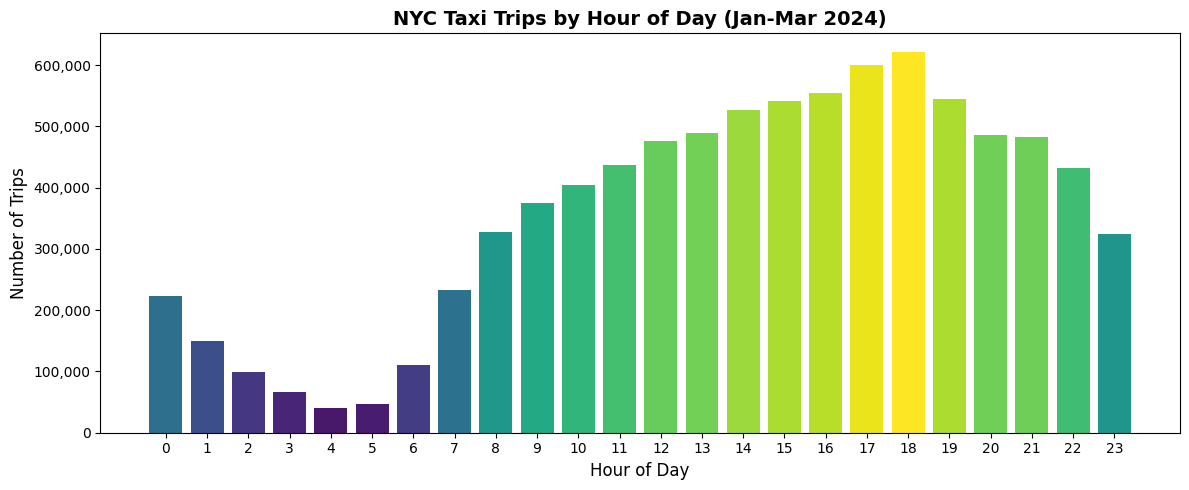

In [13]:
# ── Plot 1: Trips by Hour of Day ──
hourly = df_feat.groupBy('pickup_hour').count().orderBy('pickup_hour').toPandas()

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(hourly['pickup_hour'], hourly['count'], color=plt.cm.viridis(hourly['count'] / hourly['count'].max()))
ax.set_xlabel('Hour of Day', fontsize=12)
ax.set_ylabel('Number of Trips', fontsize=12)
ax.set_title('NYC Taxi Trips by Hour of Day (Jan-Mar 2024)', fontsize=14, fontweight='bold')
ax.set_xticks(range(0, 24))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()

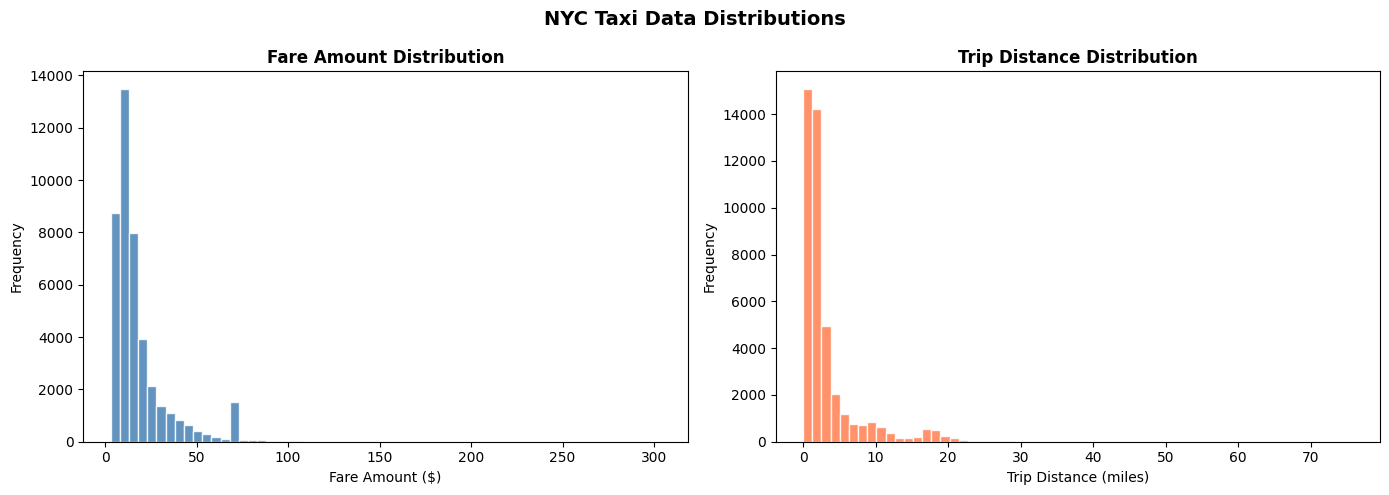

In [14]:
# ── Plot 2: Fare Amount Distribution ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(sample_pd['fare_amount'], bins=60, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].set_xlabel('Fare Amount ($)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Fare Amount Distribution', fontweight='bold')

axes[1].hist(sample_pd['trip_distance'], bins=60, color='coral', edgecolor='white', alpha=0.85)
axes[1].set_xlabel('Trip Distance (miles)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Trip Distance Distribution', fontweight='bold')

plt.suptitle('NYC Taxi Data Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

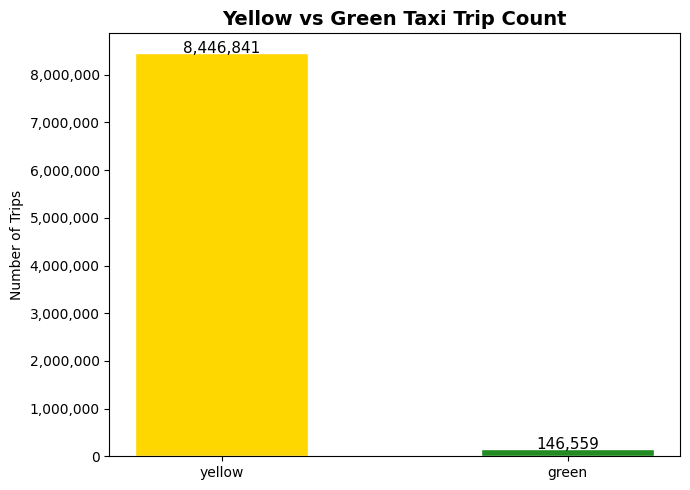

In [15]:
# ── Plot 3: Yellow vs Green Taxi Count ──
taxi_counts = df_feat.groupBy('taxi_type').count().toPandas()

fig, ax = plt.subplots(figsize=(7, 5))
colors = ['#FFD700', '#228B22']
bars = ax.bar(taxi_counts['taxi_type'], taxi_counts['count'], color=colors, edgecolor='white', width=0.5)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5000,
            f'{int(bar.get_height()):,}', ha='center', fontsize=11)
ax.set_title('Yellow vs Green Taxi Trip Count', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Trips')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()

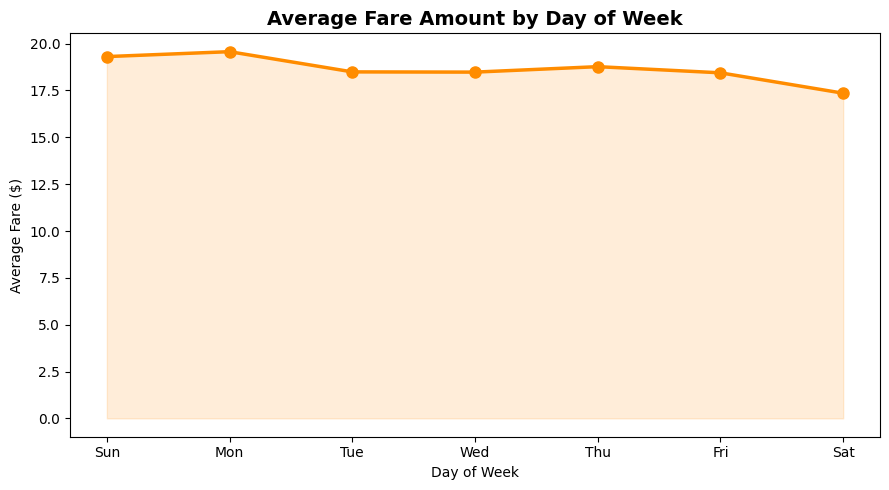

In [16]:
# ── Plot 4: Average Fare by Day of Week ──
day_names = {1:'Sun', 2:'Mon', 3:'Tue', 4:'Wed', 5:'Thu', 6:'Fri', 7:'Sat'}
dow = df_feat.groupBy('pickup_dayofweek').agg(F.avg('fare_amount').alias('avg_fare')).orderBy('pickup_dayofweek').toPandas()
dow['day'] = dow['pickup_dayofweek'].map(day_names)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(dow['day'], dow['avg_fare'], marker='o', linewidth=2.5, color='darkorange', markersize=8)
ax.fill_between(dow['day'], dow['avg_fare'], alpha=0.15, color='darkorange')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Average Fare ($)')
ax.set_title('Average Fare Amount by Day of Week', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

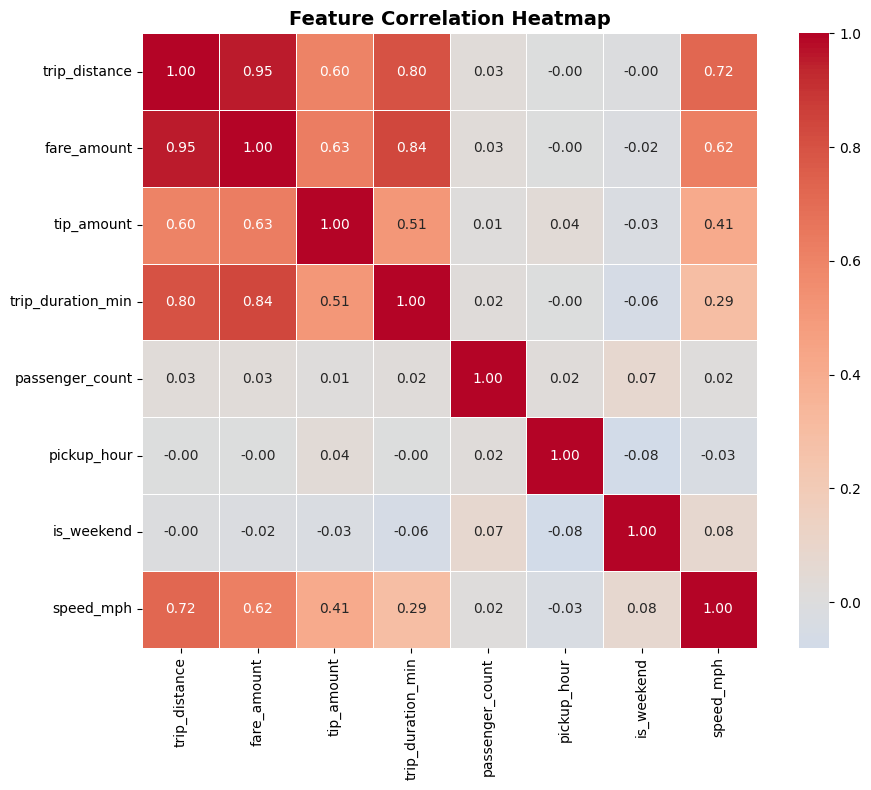

In [17]:
# ── Plot 5: Correlation Heatmap ──
corr_cols = ['trip_distance', 'fare_amount', 'tip_amount', 'trip_duration_min',
             'passenger_count', 'pickup_hour', 'is_weekend', 'speed_mph']
corr_pd = sample_pd[corr_cols].dropna()

fig, ax = plt.subplots(figsize=(10, 8))
corr_matrix = corr_pd.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, ax=ax, linewidths=0.5)
ax.set_title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

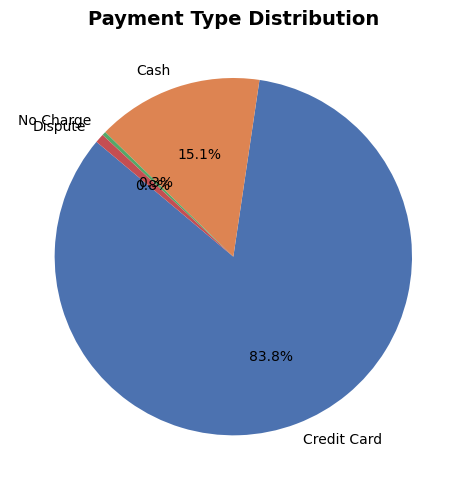

In [18]:
# ── Plot 6: Payment Type Distribution ──
payment_map = {1: 'Credit Card', 2: 'Cash', 3: 'No Charge', 4: 'Dispute'}
pay_counts = df_feat.groupBy('payment_type').count().orderBy('payment_type').toPandas()
pay_counts['label'] = pay_counts['payment_type'].map(payment_map)

fig, ax = plt.subplots(figsize=(8, 5))
wedges, texts, autotexts = ax.pie(
    pay_counts['count'], labels=pay_counts['label'],
    autopct='%1.1f%%', startangle=140,
    colors=['#4C72B0', '#DD8452', '#55A868', '#C44E52']
)
ax.set_title('Payment Type Distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 5. Supervised Learning — Algorithm 1: Linear Regression (Predict Fare Amount)

In [19]:
# Features for regression
reg_features = ['trip_distance', 'trip_duration_min', 'pickup_hour',
                'pickup_dayofweek', 'passenger_count', 'is_weekend', 'taxi_type_idx']

reg_data = df_feat.select(reg_features + ['fare_amount']).dropna()

assembler = VectorAssembler(inputCols=reg_features, outputCol='features')
scaler = StandardScaler(inputCol='features', outputCol='scaled_features')
lr = LinearRegression(featuresCol='scaled_features', labelCol='fare_amount',
                      maxIter=20, regParam=0.1)

pipeline_lr = Pipeline(stages=[assembler, scaler, lr])

train_reg, test_reg = reg_data.randomSplit([0.8, 0.2], seed=42)
model_lr = pipeline_lr.fit(train_reg)

pred_lr = model_lr.transform(test_reg)
evaluator_rmse = RegressionEvaluator(labelCol='fare_amount', predictionCol='prediction', metricName='rmse')
evaluator_r2   = RegressionEvaluator(labelCol='fare_amount', predictionCol='prediction', metricName='r2')

rmse_lr = evaluator_rmse.evaluate(pred_lr)
r2_lr   = evaluator_r2.evaluate(pred_lr)
print(f'Linear Regression — RMSE: {rmse_lr:.4f} | R²: {r2_lr:.4f}')

Linear Regression — RMSE: 4.6133 | R²: 0.9264


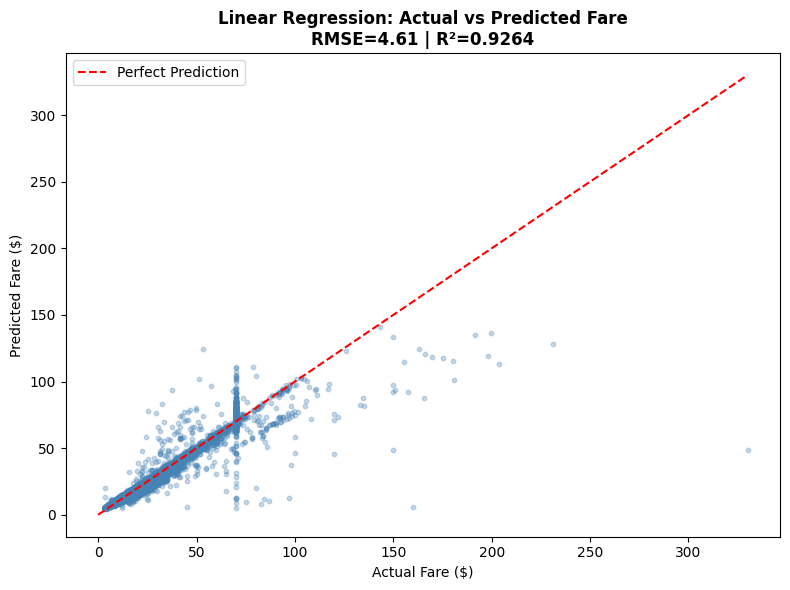

In [20]:
# Plot: Actual vs Predicted (Linear Regression)
lr_pd = pred_lr.select('fare_amount', 'prediction').sample(fraction=0.01, seed=42).toPandas()

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(lr_pd['fare_amount'], lr_pd['prediction'], alpha=0.3, s=10, color='steelblue')
lims = [0, lr_pd['fare_amount'].max()]
ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect Prediction')
ax.set_xlabel('Actual Fare ($)')
ax.set_ylabel('Predicted Fare ($)')
ax.set_title(f'Linear Regression: Actual vs Predicted Fare\nRMSE={rmse_lr:.2f} | R²={r2_lr:.4f}', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

---
## 6. Supervised Learning — Algorithm 2: Random Forest Classification (Predict High Tip)

In [21]:
# Only credit card payments have tips (payment_type == 1)
clf_features = ['trip_distance', 'trip_duration_min', 'pickup_hour',
                'pickup_dayofweek', 'passenger_count', 'fare_amount',
                'is_weekend', 'taxi_type_idx']

clf_data = df_feat.filter(F.col('payment_type') == 1) \
                  .select(clf_features + ['high_tip']).dropna()

assembler_clf = VectorAssembler(inputCols=clf_features, outputCol='features')
rf = RandomForestClassifier(featuresCol='features', labelCol='high_tip',
                            numTrees=100, maxDepth=6, seed=42)

pipeline_rf = Pipeline(stages=[assembler_clf, rf])

train_clf, test_clf = clf_data.randomSplit([0.8, 0.2], seed=42)
model_rf = pipeline_rf.fit(train_clf)

pred_rf = model_rf.transform(test_clf)
evaluator_acc = MulticlassClassificationEvaluator(labelCol='high_tip', predictionCol='prediction', metricName='accuracy')
evaluator_f1  = MulticlassClassificationEvaluator(labelCol='high_tip', predictionCol='prediction', metricName='f1')

acc = evaluator_acc.evaluate(pred_rf)
f1  = evaluator_f1.evaluate(pred_rf)
print(f'Random Forest Classification — Accuracy: {acc:.4f} | F1: {f1:.4f}')

Random Forest Classification — Accuracy: 0.8319 | F1: 0.7607


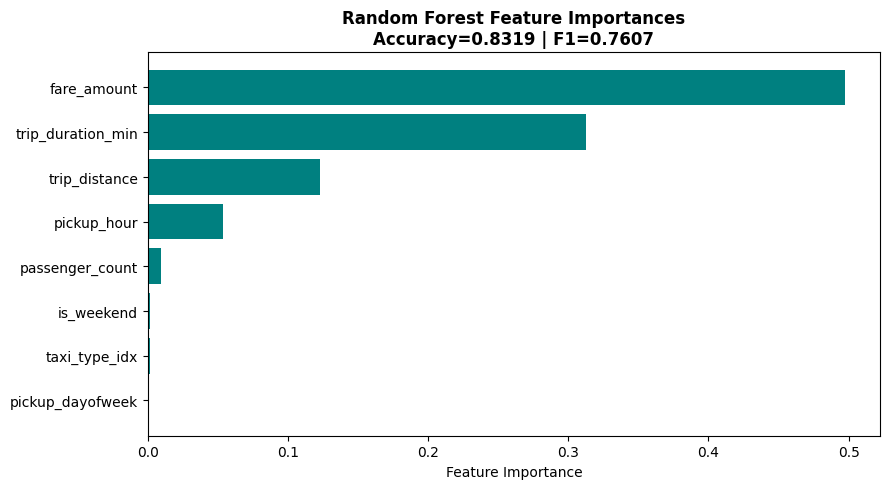

In [22]:
# Feature Importance Plot
rf_model = model_rf.stages[-1]
importances = rf_model.featureImportances.toArray()

fig, ax = plt.subplots(figsize=(9, 5))
sorted_idx = np.argsort(importances)
ax.barh([clf_features[i] for i in sorted_idx], importances[sorted_idx], color='teal')
ax.set_xlabel('Feature Importance')
ax.set_title(f'Random Forest Feature Importances\nAccuracy={acc:.4f} | F1={f1:.4f}', fontweight='bold')
plt.tight_layout()
plt.show()

---
## 7. Unsupervised Learning — K-Means Clustering

In [23]:
# Cluster trips by distance, duration, fare, and hour
km_features = ['trip_distance', 'trip_duration_min', 'fare_amount', 'pickup_hour', 'tip_percentage']
km_data = df_feat.select(km_features).dropna()

assembler_km = VectorAssembler(inputCols=km_features, outputCol='features')
scaler_km = StandardScaler(inputCol='features', outputCol='scaled_features')

# Find optimal K using Within Set Sum of Squared Errors (Elbow Method)
k_values = range(2, 9)
wssse_list = []

prep_pipeline = Pipeline(stages=[assembler_km, scaler_km])
km_prepared = prep_pipeline.fit(km_data).transform(km_data)

for k in k_values:
    kmeans = KMeans(featuresCol='scaled_features', k=k, seed=42, maxIter=20)
    km_model = kmeans.fit(km_prepared)
    wssse = km_model.summary.trainingCost
    wssse_list.append(wssse)
    print(f'K={k} | WSSSE={wssse:,.2f}')

K=2 | WSSSE=35,183,886.96
K=3 | WSSSE=22,871,530.51
K=4 | WSSSE=13,476,399.09
K=5 | WSSSE=10,441,758.81
K=6 | WSSSE=9,232,768.30
K=7 | WSSSE=8,208,346.58
K=8 | WSSSE=7,648,646.03


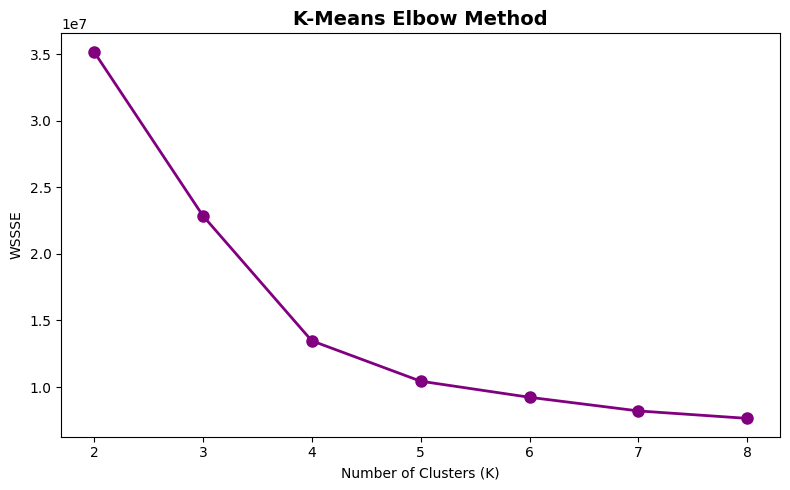

In [24]:
# Elbow Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(list(k_values), wssse_list, marker='o', linewidth=2, color='purple', markersize=8)
ax.set_xlabel('Number of Clusters (K)')
ax.set_ylabel('WSSSE')
ax.set_title('K-Means Elbow Method', fontsize=14, fontweight='bold')
ax.set_xticks(list(k_values))
plt.tight_layout()
plt.show()

In [25]:
# Train final K-Means with K=4
kmeans_final = KMeans(featuresCol='scaled_features', k=4, seed=42, maxIter=30)
km_final_model = kmeans_final.fit(km_prepared)
km_result = km_final_model.transform(km_prepared)

# Add original columns back for analysis
km_result_with_orig = km_data.withColumn('row_id', F.monotonically_increasing_id())
cluster_pd = km_result.select('prediction').toPandas()
orig_pd = km_data.toPandas()
orig_pd['cluster'] = cluster_pd['prediction']

# Cluster Analysis
cluster_summary = orig_pd.groupby('cluster')[km_features].mean().round(2)
print('=== CLUSTER CENTERS (mean values) ===')
print(cluster_summary)

=== CLUSTER CENTERS (mean values) ===
         trip_distance  trip_duration_min  fare_amount  pickup_hour  \
cluster                                                               
0                 2.04              12.47        13.85        18.21   
1                 2.10               9.50         0.01         3.00   
2                14.06              42.15        59.24        14.21   
3                 2.03              12.18        13.80         8.63   

         tip_percentage  
cluster                  
0                 22.51  
1             400000.00  
2                 16.22  
3                 20.58  


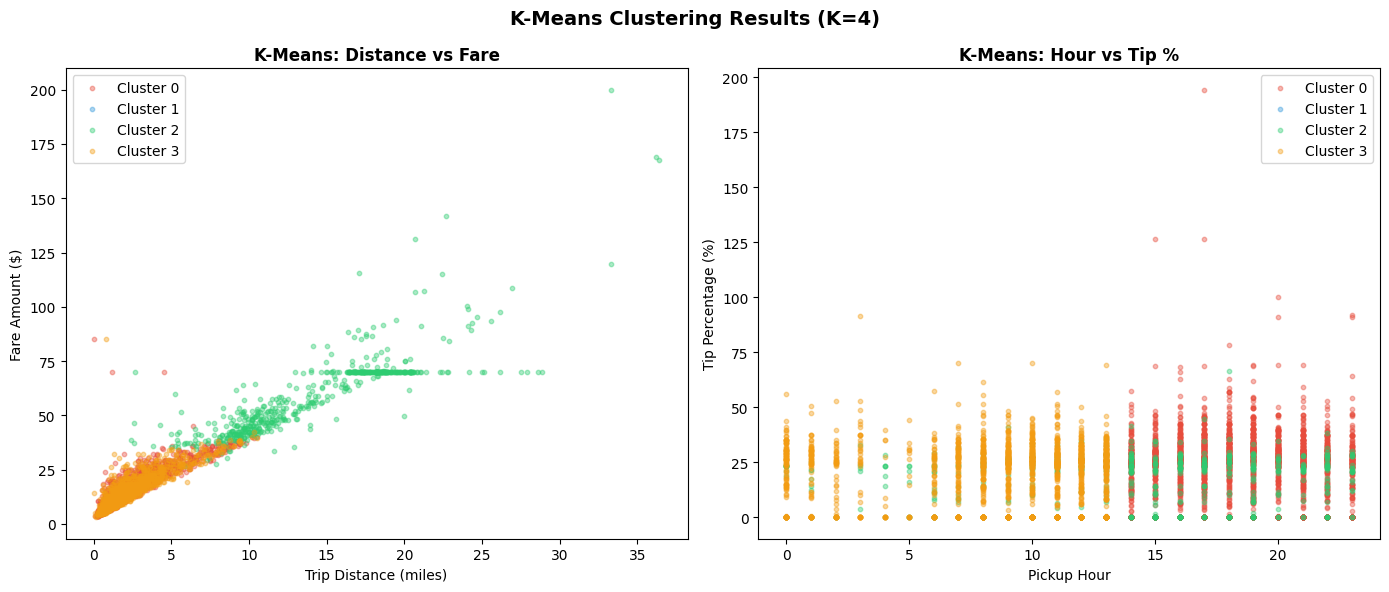

In [26]:
# Visualize clusters: Trip Distance vs Fare Amount
sample_km = orig_pd.sample(n=min(5000, len(orig_pd)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12']

for cluster_id in range(4):
    subset = sample_km[sample_km['cluster'] == cluster_id]
    axes[0].scatter(subset['trip_distance'], subset['fare_amount'],
                    c=colors[cluster_id], label=f'Cluster {cluster_id}', alpha=0.4, s=10)
axes[0].set_xlabel('Trip Distance (miles)')
axes[0].set_ylabel('Fare Amount ($)')
axes[0].set_title('K-Means: Distance vs Fare', fontweight='bold')
axes[0].legend()

for cluster_id in range(4):
    subset = sample_km[sample_km['cluster'] == cluster_id]
    axes[1].scatter(subset['pickup_hour'], subset['tip_percentage'],
                    c=colors[cluster_id], label=f'Cluster {cluster_id}', alpha=0.4, s=10)
axes[1].set_xlabel('Pickup Hour')
axes[1].set_ylabel('Tip Percentage (%)')
axes[1].set_title('K-Means: Hour vs Tip %', fontweight='bold')
axes[1].legend()

plt.suptitle('K-Means Clustering Results (K=4)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 8. Neural Network (Keras) — Predict Fare Amount

In [27]:
# Sample data for Neural Network (Keras works on Pandas)
nn_features = ['trip_distance', 'trip_duration_min', 'pickup_hour',
               'pickup_dayofweek', 'passenger_count', 'is_weekend', 'taxi_type_idx']
nn_target = 'fare_amount'

# Sample 200k rows for training
nn_pd = df_feat.select(nn_features + [nn_target]).dropna() \
               .sample(fraction=0.05, seed=42).toPandas()

X = nn_pd[nn_features].values
y = nn_pd[nn_target].values

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
sk_scaler = SklearnScaler()
X_train_scaled = sk_scaler.fit_transform(X_train)
X_test_scaled  = sk_scaler.transform(X_test)

print(f'Training samples: {X_train.shape[0]:,}')
print(f'Test samples:     {X_test.shape[0]:,}')

Training samples: 343,400
Test samples:     85,851


In [28]:
# Build Neural Network
tf.random.set_seed(42)

model_nn = keras.Sequential([
    keras.layers.Input(shape=(len(nn_features),)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(1)  # Regression output
])

model_nn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

model_nn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,161 (47.50 KB)

 Trainable params: 11,777 (46.00 KB)

 Non-trainable params: 384 (1.50 KB)

In [29]:
# Train Neural Network
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model_nn.fit(
    X_train_scaled, y_train,
    validation_split=0.15,
    epochs=50,
    batch_size=512,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
571/571 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 68.6390 - mae: 4.2783 - val_loss: 20.2928 - val_mae: 1.3395
Epoch 2/50
571/571 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 25.5011 - mae: 2.1824 - val_loss: 18.7614 - val_mae: 1.1828
Epoch 3/50
571/571 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 24.5872 - mae: 2.1146 - val_loss: 18.1211 - val_mae: 1.1554
Epoch 4/50
571/571 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 23.7114 - mae: 2.0703 - val_loss: 17.7089 - val_mae: 1.1408
Epoch 5/50
571/571 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 22.9829 - mae: 2.0349 - val_loss: 17.5941 - val_mae: 1.1433
Epoch 6/50
571/571 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 22.5020 - mae: 2.0082 - val_loss: 17.7176 - val_mae: 1.1290
Epoch 7/50
571/571 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 22.0330 - mae: 1.9600 - val_loss: 17.8954 - val_mae: 1.1971
Epoch 8/50
571/571 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 21.5091 - mae: 1.9069 - val_loss: 17.7880 - val_mae: 1.1537
Epoch 9/50
571/571 ━━━━━━━━━━━━━━━━━━━━ 

In [30]:
# Evaluate Neural Network
y_pred_nn = model_nn.predict(X_test_scaled).flatten()
rmse_nn = np.sqrt(mean_squared_error(y_test, y_pred_nn))
r2_nn   = r2_score(y_test, y_pred_nn)
print(f'Neural Network — RMSE: {rmse_nn:.4f} | R²: {r2_nn:.4f}')

2683/2683 ━━━━━━━━━━━━━━━━━━━━ 1s 433us/step
Neural Network — RMSE: 3.7645 | R²: 0.9497


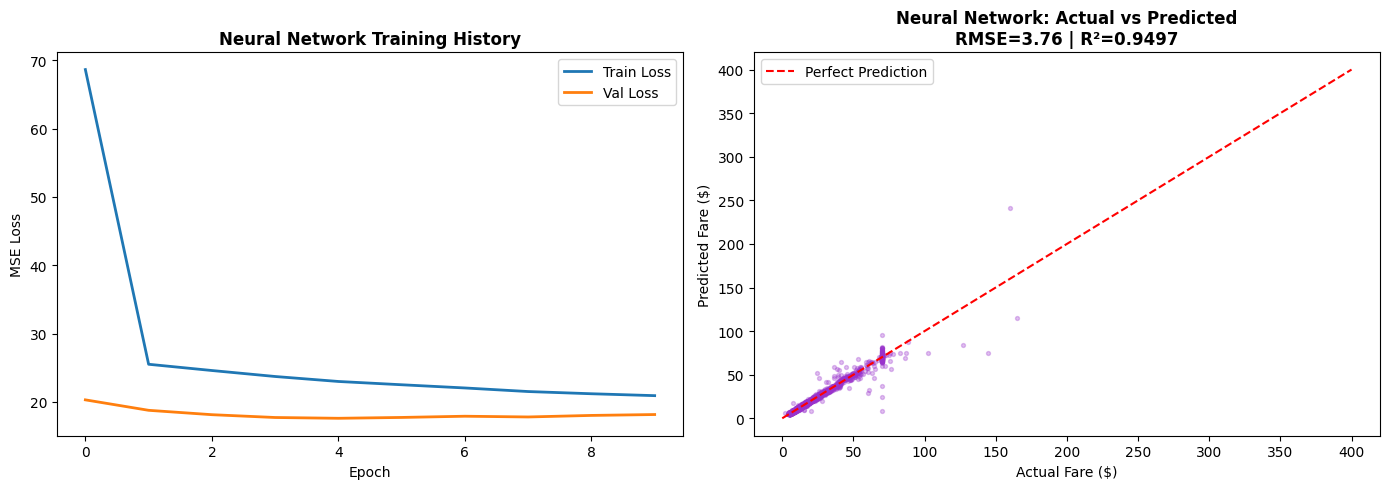

In [31]:
# Plot Training History + Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training history
axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE Loss')
axes[0].set_title('Neural Network Training History', fontweight='bold')
axes[0].legend()

# Actual vs Predicted
sample_idx = np.random.choice(len(y_test), size=min(3000, len(y_test)), replace=False)
axes[1].scatter(y_test[sample_idx], y_pred_nn[sample_idx], alpha=0.3, s=8, color='darkorchid')
lim_max = max(y_test.max(), y_pred_nn.max())
axes[1].plot([0, lim_max], [0, lim_max], 'r--', linewidth=1.5, label='Perfect Prediction')
axes[1].set_xlabel('Actual Fare ($)')
axes[1].set_ylabel('Predicted Fare ($)')
axes[1].set_title(f'Neural Network: Actual vs Predicted\nRMSE={rmse_nn:.2f} | R²={r2_nn:.4f}', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 9. Model Comparison Summary

In [32]:
print('=' * 55)
print('           MODEL PERFORMANCE SUMMARY')
print('=' * 55)
print(f'  Linear Regression (Spark MLlib)')
print(f'    Task   : Predict Fare Amount')
print(f'    RMSE   : {rmse_lr:.4f}')
print(f'    R²     : {r2_lr:.4f}')
print('-' * 55)
print(f'  Random Forest Classifier (Spark MLlib)')
print(f'    Task   : Predict High Tip (>15%)')
print(f'    Accuracy: {acc:.4f}')
print(f'    F1 Score: {f1:.4f}')
print('-' * 55)
print(f'  K-Means Clustering (Spark MLlib)')
print(f'    Task   : Trip Pattern Clustering')
print(f'    K      : 4 clusters')
print('-' * 55)
print(f'  Neural Network (Keras/TensorFlow)')
print(f'    Task   : Predict Fare Amount')
print(f'    RMSE   : {rmse_nn:.4f}')
print(f'    R²     : {r2_nn:.4f}')
print('=' * 55)

           MODEL PERFORMANCE SUMMARY
  Linear Regression (Spark MLlib)
    Task   : Predict Fare Amount
    RMSE   : 4.6133
    R²     : 0.9264
-------------------------------------------------------
  Random Forest Classifier (Spark MLlib)
    Task   : Predict High Tip (>15%)
    Accuracy: 0.8319
    F1 Score: 0.7607
-------------------------------------------------------
  K-Means Clustering (Spark MLlib)
    Task   : Trip Pattern Clustering
    K      : 4 clusters
-------------------------------------------------------
  Neural Network (Keras/TensorFlow)
    Task   : Predict Fare Amount
    RMSE   : 3.7645
    R²     : 0.9497


In [33]:
# Stop Spark
spark.stop()
print('Spark session stopped.')

Spark session stopped.
